## RaNNDy for graphons

In [4]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt
import jax.random as random
import importlib
import scipy as sp
import time
import sys
import optimal_ranndy
import utils
importlib.reload(optimal_ranndy)
importlib.reload(utils)
from utils import nice_2d_plot, nice_3d_plot
from optimal_ranndy import RaNNDy, VAMPnets
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")

import d3s.networks as networks
import d3s.kernels as kernels

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'         
plt.rcParams['font.serif'] = ['Computer Modern Serif']  


## Do unsymmetric graphon experiments

In [2]:
type_graphon = 'sym'  # 'sym' or 'unsym'

##TODO: load data from .mat file instead of recomputing everything every time

data = sp.io.loadmat(f"./data/graphon_data_{type_graphon}.mat")
Xd = data['Xd']
Yd = data['Yd']
x = data['x'].squeeze()
degree = data['degree'].squeeze()
Zw = data['Zw']
Zp = data['Zp']
pi_x = data['pi_x'].squeeze()


In [ ]:
##TODO: to generate data from scratch, uncomment the following code and comment out the data loading above

# if type_graphon == 'sym':
#     #%% define symmetric graphon
#     def w(x, y):
#         """
#         Symmetric graphon with three peaks.
#         """
#         return (
#             0.2 * np.exp(-((x - 0.2) ** 2 + (y - 0.2) ** 2) / 0.02)
#             + 0.1 * np.exp(-((x - 0.5) ** 2 + (y - 0.5) ** 2) / 0.02)
#             + 0.2 * np.exp(-((x - 0.8) ** 4 + (y - 0.8) ** 4) / 0.0005)
#         )

# elif type_graphon == 'unsym':
#     #%% define unsymmetric graphon
#     def w(x, y):
#         """
#         Unsymmetric graphon with three peaks.
#         """
#         return (
#             0.2 * np.exp(-((x - 0.15) ** 2 + (y - 0.3) ** 2) / 0.008)
#             + 0.2 * np.exp(-((x - 0.3) ** 2 + (y - 0.45) ** 2) / 0.008)
#             + 0.2 * np.exp(-((x - 0.45) ** 2 + (y - 0.15) ** 2) / 0.008)
#             + 0.15 * np.exp(-((x - 0.75) ** 2 + (y - 0.75) ** 2) / 0.02)
#         )

# g = networks.graphon(w)

# n = 101
# x = np.linspace(0, 1, n)  # equidistant grid points
# xx, yy = np.meshgrid(x, x)
# Zw = np.zeros_like(xx)
# Zp = np.zeros_like(xx)
# for i in range(n):
#     for j in range(n):
#         Zw[i, j] = g.w(xx[i, j], yy[i, j])

# # %% plot degree function
# degree = np.zeros_like(x)
# for i in range(n):
#     degree[i] = g.d(x[i])

# # %% plot transition density function
# for i in range(n):
#     for j in range(n):
#         Zp[i, j] = g.p(xx[i, j], yy[i, j])


# # %% estimate invariant density
# # %% compute one long random walk
# m = 20000
# r = g.randomWalk(0.5, m)  # 0.5 is the initial position of the random walker

# Xd = r[:-1].reshape([1, m])  #  data matrices ...
# Yd = r[1:].reshape([1, m])  #  ... for EDMD

# # %% estimate invariant density
# k = kernels.gaussianKernel(0.03)
# pi = kernels.kde(Xd, k)
# pi_x = pi(x[np.newaxis, :]).squeeze()

# graphon_data = {'Xd': Xd, 'Yd': Yd, 'x': x, 'degree': degree, 'Zw': Zw, 'Zp': Zp, 'pi_x': pi_x}
# sp.io.savemat(f"graphon_data_{type_graphon}.mat", graphon_data)


<>:21: SyntaxWarning: invalid escape sequence '\p'
<>:21: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_5988/1651173770.py:21: SyntaxWarning: invalid escape sequence '\p'
  with nice_2d_plot(xlabel='$x$', ylabel='$\pi(x)$') as (fig5, ax5):


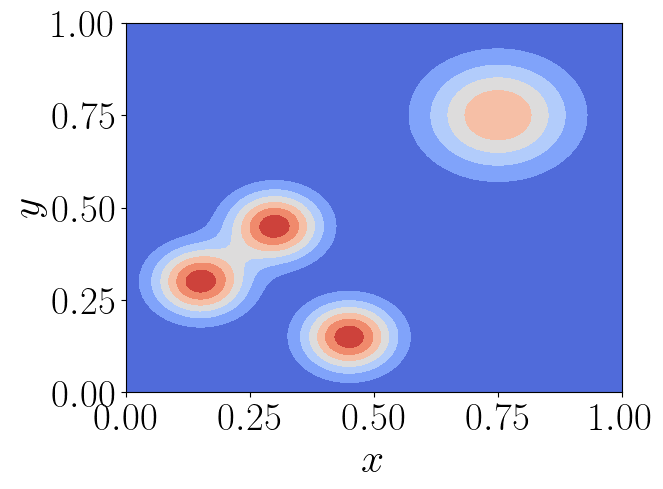

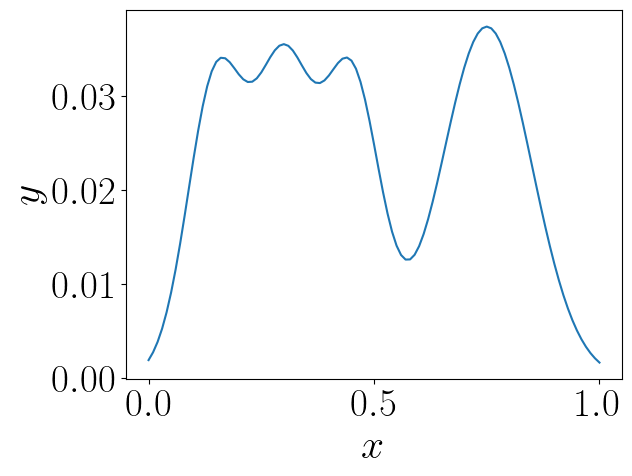

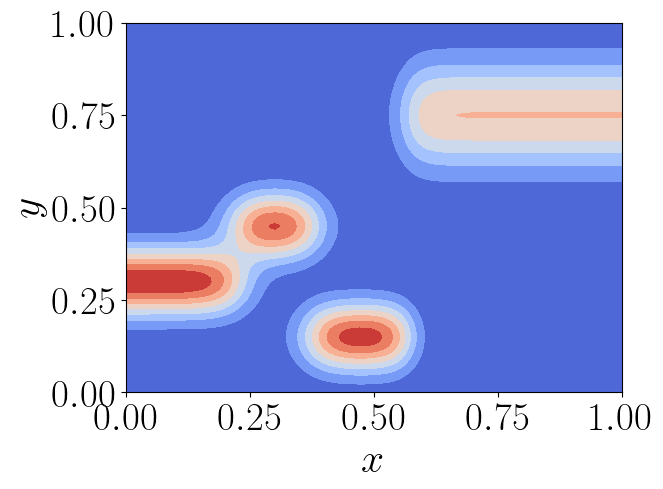

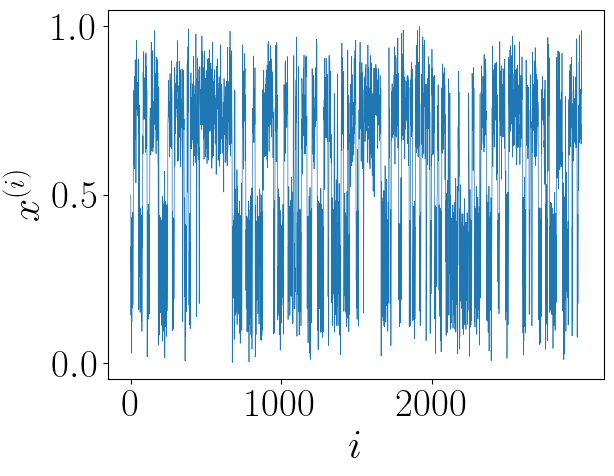

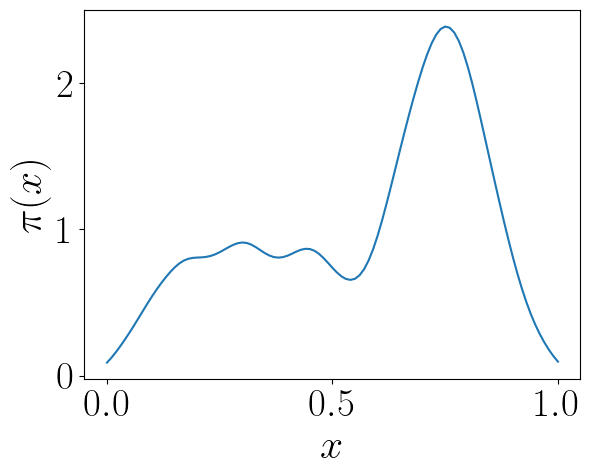

In [ ]:
## plotting graphon

with nice_2d_plot(xlabel='$x$', ylabel='$y$') as (fig1, ax1):
    ax1.contourf(xx, yy, Zw, cmap=plt.cm.coolwarm)
    #ax1.view_init(elev=35, azim=-70, roll=0)
    #plt.savefig(f'../figures/{type_graphon}_graphon_w_contour.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot(xlabel='$x$', ylabel='$y$') as (fig2, ax2):
    ax2.plot(x, degree)
    #plt.savefig(f'../figures/{type_graphon}_graphon_degree.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot(xlabel='$x$', ylabel='$y$') as (fig3, ax3):
    ax3.contourf(xx, yy, Zp, cmap=plt.cm.coolwarm)
    #plt.savefig(f'../figures/{type_graphon}_graphon_p_contour.pdf', bbox_inches='tight', dpi=300)
    
with nice_2d_plot(xlabel='$i$', ylabel='$x^{(i)}$', xticks=np.arange(0, 3000, 1000)) as (fig4, ax4):
    ax4.plot(r[:3000], linewidth=0.5)
    #plt.savefig(f'../figures/{type_graphon}_graphon_rw.pdf', bbox_inches='tight', dpi=300)


with nice_2d_plot(xlabel='$x$', ylabel='$\pi(x)$') as (fig5, ax5):
    ax5.plot(x, pi_x)

## Apply RaNNDy

AttributeError: 'Axes' object has no attribute 'plot_surface'

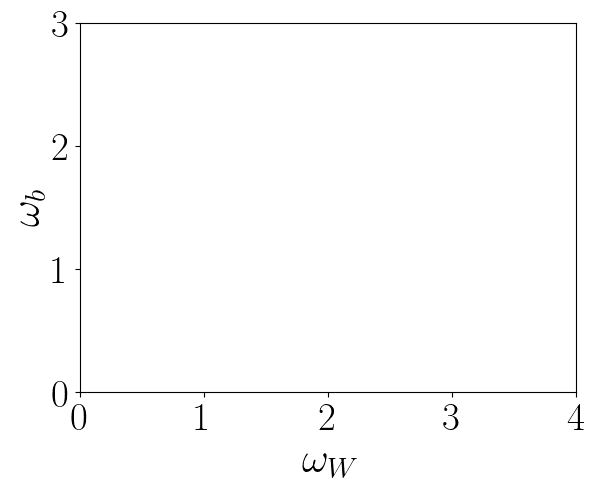

In [ ]:
# # # Experiment to plot loss surface of RaNNDy

# # %matplotlib inline


# random_state = 0  # Random state for reproducibility
# n_eigfuncs = 5  
# key = random.PRNGKey(seed=0)
# w_init = [1.0, 1.0]
# dist_w_list = ['normal', 'lecun_normal', 'he_uniform', 'uniform', 'glorot_uniform']
# dist_b_list = ['normal', 'uniform', 'zeros', 'ones']
# #omega_b_list = [0.001, 0.08, 0.1, 0.3, 0.7, 1.0]
# #omega_w_list = [0.001, 0.02, 0.1, 0.3, 0.5, 0.8, 1.0, 2.0, 3.0, 5.0, 6.0, 8.0]
# vampscores_exp_ls = np.zeros((len(dist_w_list), len(dist_b_list)))

# for i in range(len(dist_w_list)):
#     for j in range(len(dist_b_list)):
#         ranndy_exp = RaNNDy(
#         X=Xd,
#         operator='koopman',
#         hidden_sizes=[256, 512, 256],
#         activation="cos",
#         init_weights_dist=dist_w_list[i], 
#         init_weights_std=1.0,
#         init_bias_dist=dist_b_list[j],
#         init_bias_std=1.0,
#         random_state=random_state,
#     )
#         eigval_exp, _ = ranndy_exp.operator_eig_decomp(w=[None, None], X=Xd, Y=Yd, Z=None, n=n_eigfuncs, epsilon=1e-5)
#         vampscores_exp_ls[i, j] = np.sum(np.real(eigval_exp)[:3])

# omw, omb = np.meshgrid(range(len(dist_w_list)), range(len(dist_b_list)))

# with nice_2d_plot(xlabel='Weights Distribution', ylabel='Bias Distribution', xticks=range(len(dist_w_list)), yticks=range(len(dist_b_list))) as (fig15, ax15):
#     cp = ax15.imshow(vampscores_exp_ls.T, cmap=plt.cm.coolwarm)
    
#     ax15.set_xticklabels(dist_w_list, rotation=45, fontsize=22)
#     ax15.set_yticklabels(dist_b_list, fontsize=22)
#     ax15.xaxis.labelpad = 15
#     ax15.yaxis.labelpad = 15
#     #ax15.set_zticklabels([])
#     cbar = fig15.colorbar(cp, ax=ax15, shrink=0.8, pad=0.1)
#     cbar.set_label('VAMP Score', size=25)
#     cbar.ax.tick_params(labelsize=15) 
#     #ax15.view_init(elev=35, azim=-65, roll=0)
#     #fig15.savefig('../figures/symgraphon_gridsearch_dists.pdf', bbox_inches='tight', dpi=300)
#     plt.show()


In [7]:
## Optimize activation of RaNNDy

random_state = 0  # Random state for reproducibility
n_eigfuncs = 7  
key = random.PRNGKey(seed=0)
w_init = [0.1, 0.1]

if type_graphon == 'sym':
    operator = 'koopman'
else:
    operator = 'forward_backward'

ranndy = RaNNDy(
        X=Xd,
        operator=operator,
        hidden_sizes=[1024, 256],
        activation="tanh",
        init_weights_dist='normal', 
        init_weights_std=1.0,
        init_bias_dist='uniform',
        init_bias_std=1.0,
        random_state=random_state,
    )

start_time = time.time()  # Start time for RaNNDy eigendecomposition

w_gd, loss_w, w_vals, _ = ranndy.optimize_activation(w_init=w_init, X=Xd, Y=Yd, n=n_eigfuncs, epochs=30, lr=0.5, lr_schedule='linear', get_epoch=1, epsilon=1e-7, tol=1e-5, verbose=True)

w = w_gd                       # Select parameter values

# eigvals and eigenvectors approximation
eigvals_r, eigvecs_r = ranndy.operator_eig_decomp(
    w=w,
    X=Xd,
    Y=Yd,
    Z=None,
    n=n_eigfuncs,
    epsilon=1e-5,
    )

end_time = time.time()  # End time for RaNNDy eigendecomposition
time_rnn = end_time - start_time
print(f"RNN eigendecomposition time: {time_rnn:.2f} seconds")

Epoch 0, Loss: -1.8943
Time for one step of RaNNDy optimization: 1.6837 seconds
Epoch 1, Loss: -2.5894
Time for one step of RaNNDy optimization: 1.8134 seconds
RNN eigendecomposition time: 5.90 seconds


In [6]:
w_vals

[[Array(0.59999657, dtype=float32), Array(-0.39999563, dtype=float32)],
 [Array(0.59999657, dtype=float32), Array(-0.39999563, dtype=float32)]]

In [8]:
eigvals_r

Array([9.99995768e-01+0.j, 9.33466017e-01+0.j, 6.82059646e-01+0.j,
       1.45597905e-02+0.j, 5.27653145e-03+0.j, 1.41195221e-06+0.j,
       1.02905176e-06+0.j], dtype=complex64)

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\o'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_19062/295087151.py:4: SyntaxWarning: invalid escape sequence '\m'
  ax6.plot(np.abs(np.array(loss_w)), '-o', label='$\mathrm{tr}(A)$')
/tmp/ipykernel_19062/295087151.py:5: SyntaxWarning: invalid escape sequence '\m'
  ax6.set_ylabel(ylabel='$\mathrm{tr}(A)$', color='tab:blue', fontsize=30)
/tmp/ipykernel_19062/295087151.py:8: SyntaxWarning: invalid escape sequence '\o'
  ax6s.set_ylabel('$\omega_W$', color='tab:red', fontsize=30)


Final w:  [Array(0.59999657, dtype=float32), Array(-0.39996392, dtype=float32)]


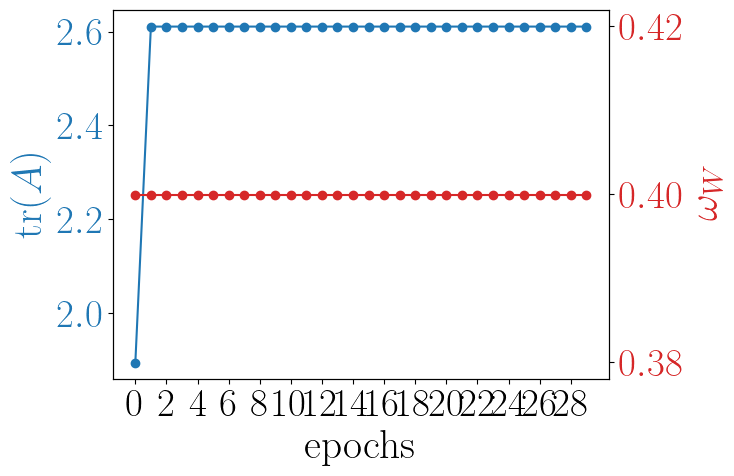

In [ ]:
## Plotting the loss and the evolution of the parameter w during optimization

print('Final w: ', w_gd)

with nice_2d_plot(xlabel='epochs', xticks=np.arange(0, 30, 2)) as (fig6, ax6):
    ax6.plot(np.abs(np.array(loss_w)), '-o', label='$\mathrm{tr}(A)$')
    ax6.set_ylabel(ylabel='$\mathrm{tr}(A)$', color='tab:blue', fontsize=30)
    ax6.tick_params(axis='y', labelcolor='tab:blue', labelsize=28)
    ax6s = ax6.twinx()
    ax6s.set_ylabel('$\omega_W$', color='tab:red', fontsize=30)
    # ax6s.set_yticks(np.arange(0, 8, 2))
    ax6s.tick_params(axis='y', labelcolor='tab:red', labelsize=28)
    ax6s.plot(np.abs(np.array(w_vals)[:, 1]), '-o', color='tab:red')
    
    #plt.savefig(f'../figures/{type_graphon}_graphon_loss.pdf', bbox_inches='tight', dpi=300)

In [ ]:
## normalize eigenfunctions
domain_eigf = x.reshape(1, -1) # Xd   # Omega.midpointGrid()

##eigfs of the Koopman operator
eigfuncs_r = np.array(ranndy.eigenfunctions(
        w=w,
        eigvecs=eigvecs_r,
        domain=domain_eigf,
        ))

##eigfs of the Perron--Frobenius operator
eigfuncs_hat_r = np.array(ranndy.eigenfunctions(
        w=w,
        eigvecs=eigvecs_r,
        domain=domain_eigf,
        ))

## Normalize eigenfunctions
for i in range(n_eigfuncs):
    eigfuncs_i = lambda x: np.real((eigvecs_r[i, :].T @ ranndy.apply(opt_params, np.array([[x]]), w)))[0]  # noqa: E731
    f = lambda x: eigfuncs_i(x) ** 2 * pi(x)  # noqa: E731
    I = np.sqrt(sp.integrate.quad(f, 0, 1)[0])
    eigfuncs_r[i, :] = eigfuncs_r[i, :] / I  # normalize w.r.t. pi-weighted norm

    eigfuncs_hat_r[i, :] = eigfuncs_hat_r[i, :] * pi_x
    eigfuncs_hat_i = lambda x: np.real((eigvecs_r[i, :].T @ ranndy.apply(opt_params, np.array([[x]]), w)))[0] * pi(x)  # noqa: E731
    f = lambda x: eigfuncs_hat_i(x) ** 2 / pi(x)  # noqa: E731
    I = np.sqrt(sp.integrate.quad(f, 0, 1)[0])
    eigfuncs_hat_r[i, :] = eigfuncs_hat_r[i, :] / I  # normalize w.r.t. 1/pi-weighted norm


eigfuncs_r = np.real(eigfuncs_r/np.amax(eigfuncs_r))

eigfuncs_hat_r = np.real(eigfuncs_hat_r/np.amax(eigfuncs_hat_r))

<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:8: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_19062/394334176.py:8: SyntaxWarning: invalid escape sequence '\l'
  with nice_2d_plot(xlabel='$i$', ylabel='$\lambda_i$', xticks=np.arange(1, 6, 1)) as (fig7, ax7):
/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:352: UserWarning: One of the clusters is empty. Re-run kmeans with a different initialization.
  return fun(*args, **kwargs)


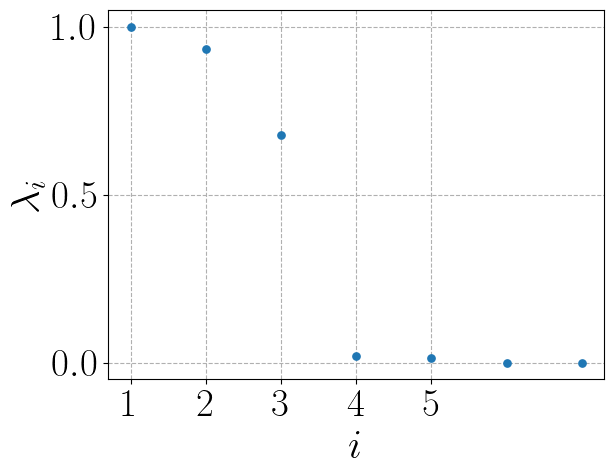

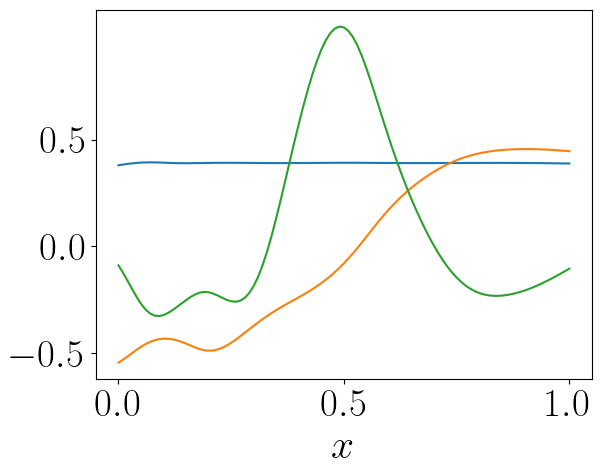

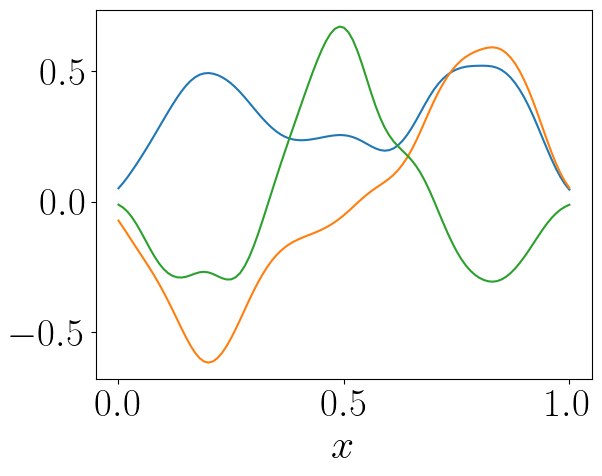

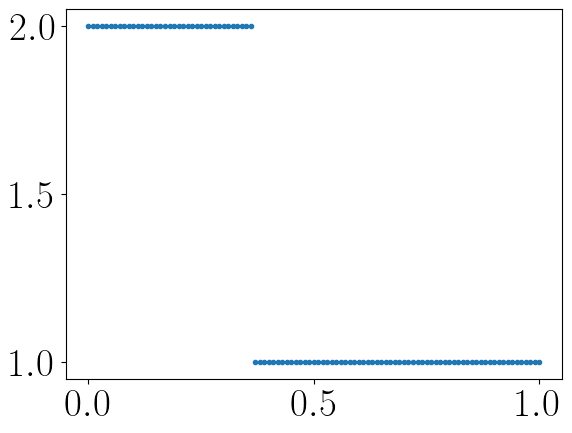

In [ ]:
## plotting results for Koopman and Perron-Frobenius eigenfunctions

if type_graphon == 'sym':
    rank_approx = 3
else:
    rank_approx = 4

_, lr = sp.cluster.vq.kmeans2(np.real(eigfuncs_r[:rank_approx, :]).T, rank_approx)  # apply k-means clustering

with nice_2d_plot(xlabel='$i$', ylabel='$\lambda_i$', xticks=np.arange(1, 6, 1)) as (fig7, ax7):
    ax7.plot(np.arange(1, 8, 1), jnp.real(eigvals_r), ".", markersize=10.5)
    plt.grid(which="minor", linestyle=":")
    plt.grid(which="major", linestyle="--")
    #plt.savefig(f'../figures/{type_graphon}_graphon_eigvals.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot(xlabel='$x$', yticks=np.arange(-1, 1, 0.5)) as (fig8, ax8):
    ax8.plot(x, -eigfuncs_r[:rank_approx, :].T)
    #plt.savefig(f'../figures/{type_graphon}_graphon_Keigfuncs.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot(xlabel='$x$') as (fig9, ax9):
    ax9.plot(x, -eigfuncs_hat_r[:rank_approx, :].T)
    #plt.savefig(f'../figures/{type_graphon}_graphon_Peigfuncs.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot() as (fig10, ax10):
    ax10.plot(x, lr, ".")
    #plt.savefig(f'../figures/{type_graphon}_graphon_eigfuncs_clusters.pdf', bbox_inches='tight', dpi=300)


In [34]:
Z1r = np.zeros_like(xx)
Z2r = np.zeros_like(xx)
for i in range(n):
    for j in range(n):
        for k in range(4):  # use first four eigenfunctions for the reconstruction
            Z1r[i, j] = Z1r[i, j] + np.array(eigvals_r)[k] * eigfuncs_hat_r[k, i] * eigfuncs_r[k, j]  # p
            Z2r[i, j] = Z2r[i, j] + np.array(eigvals_r)[k] * eigfuncs_hat_r[k, i] * eigfuncs_hat_r[k, j]  # w

/tmp/ipykernel_5988/602230295.py:6: ComplexWarning: Casting complex values to real discards the imaginary part
  Z1r[i, j] = Z1r[i, j] + np.array(eigvals_r)[k] * eigfuncs_hat_r[k, i] * eigfuncs_r[k, j]  # p
/tmp/ipykernel_5988/602230295.py:7: ComplexWarning: Casting complex values to real discards the imaginary part
  Z2r[i, j] = Z2r[i, j] + np.array(eigvals_r)[k] * eigfuncs_hat_r[k, i] * eigfuncs_hat_r[k, j]  # w


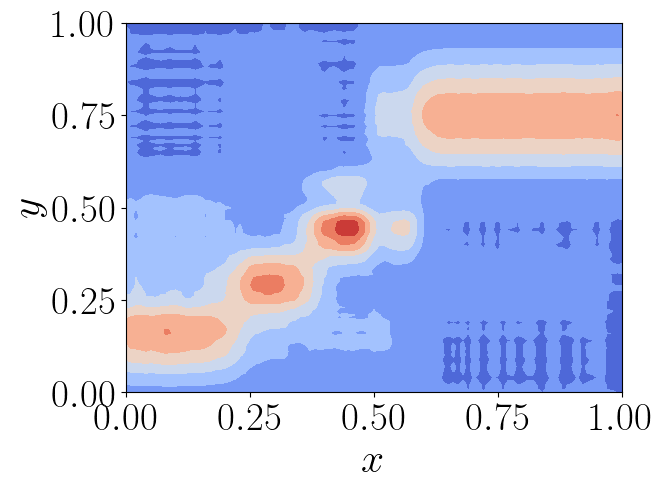

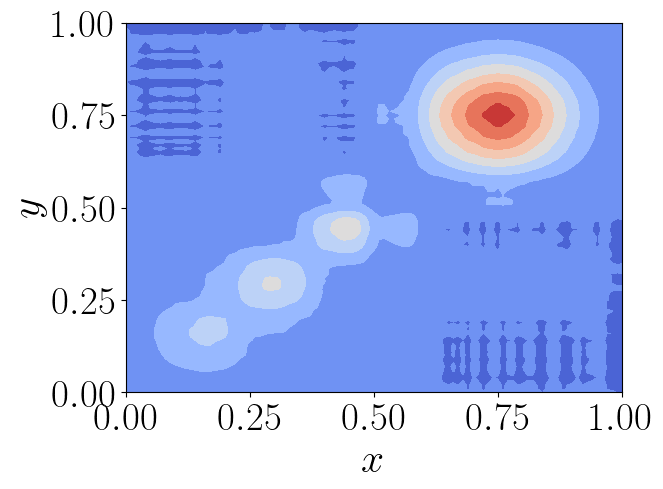

In [36]:
## plotting reconstructions

with nice_2d_plot(xlabel='$x$', ylabel='$y$') as (fig11, ax11):
    ax11.contourf(xx, yy, Z1r, cmap=plt.cm.coolwarm)
    plt.show()
    #fig11.savefig(f'../figures/{type_graphon}_graphon_reconst_p.pdf', bbox_inches='tight', dpi=300)

with nice_2d_plot(xlabel='$x$', ylabel='$y$') as (fig12, ax12):
    ax12.contourf(xx, yy, Z2r, cmap=plt.cm.coolwarm)
    #plt.savefig(f'../figures/{type_graphon}_graphon_reconst_w.pdf', bbox_inches='tight', dpi=300)


## comparsion between RaNNDy and VAMPnets

In [5]:
## compare RaNNDy with VAMPnets

random_state = 0  # Random state for reproducibility
n_eigfuncs = 5  
key = random.PRNGKey(seed=random_state)
w_init = [0.01, 1.0]      #TODO: change the initialization of RaNNDy for the graphon data

ranndy_exp = RaNNDy(
        X=Xd,
        operator='koopman',
        hidden_sizes=[256, 512, 256],
        activation="tanh",
        init_weights_dist='normal', 
        init_weights_std=w_init[0],
        init_bias_dist='uniform',
        init_bias_std=w_init[1],
        random_state=random_state,
    )

vampnet_exp = VAMPnets(
    X=Xd,
    operator='koopman',
    hidden_sizes=[256, 512, 256],
    activation='tanh',
    init_weights_dist='normal', 
    init_weights_std=0.1,
    init_bias_dist='uniform',
    init_bias_std=1.0,
    softmax_output=False,
    random_state=random_state,
    )

params_init = vampnet_exp.init(key, jnp.ones_like(Xd), w=[None, None])

epochs = 10
get_epoch = 1


params_f, loss_vampnet, times_vampnet = vampnet_exp.training(params_init=params_init, X=Xd, Y=Yd, epochs=epochs, lr=1e-2, lr_schedule='constant', decay_steps=1, get_epoch=get_epoch, epsilon=1e-10)   # Remeber correct step size for VAMPnet too large diverges


w_gd_exp, loss_ranndy, _, times_ranndy = ranndy_exp.optimize_activation(w_init=w_init, X=Xd, Y=Yd, params=params_init, n=n_eigfuncs, epochs=epochs, lr=0.5, lr_schedule='constant', decay_steps=1, get_epoch=get_epoch,epsilon=1e-7)


# eigvals_r_exp, _ = ranndy_exp.operator_eig_decomp(w=w_gd_exp, X=Xd, Y=Yd, Z=None, n=n_eigfuncs, epsilon=1e-7)


# Kv, eigvals_v_exp, _ = vampnet_exp.spectrum_approximation(params=params_f, X=Xd, Y=Yd, n=n_eigfuncs, operator='koopman')


Time for one step of VAMPnet optimization: 2.0833 seconds
Epoch 0, Loss: -1.7978
Time for one step of VAMPnet optimization: 1.3155 seconds
Epoch 1, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.2023 seconds
Epoch 2, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.3007 seconds
Epoch 3, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.0627 seconds
Epoch 4, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.0858 seconds
Epoch 5, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.0195 seconds
Epoch 6, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.0951 seconds
Epoch 7, Loss: -1.0000
Time for one step of VAMPnet optimization: 0.9859 seconds
Epoch 8, Loss: -1.0000
Time for one step of VAMPnet optimization: 1.2988 seconds
Epoch 9, Loss: -1.0000
Epoch 0, Loss: -1.0000
Time for one step of RaNNDy optimization: 1.7460 seconds
Epoch 1, Loss: -2.6035
Time for one step of RaNNDy optimization: 1.6984 seconds
Epoch 2, Loss: -2.5915
Time fo

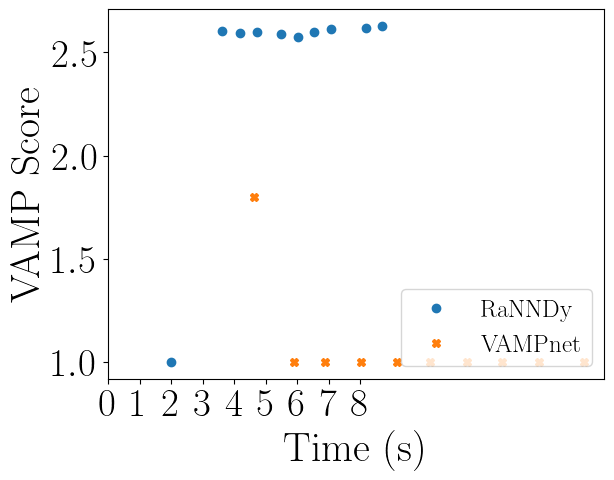

In [4]:

with nice_2d_plot(xlabel='Time (s)', ylabel='VAMP Score') as (fig14, ax14):
    ax14.plot(times_ranndy[:], (-np.array(loss_ranndy[:])), 'o', label='RaNNDy')
    ax14.plot(times_vampnet[:], (-np.array(loss_vampnet[:])), 'X', label='VAMPnet')
    ax14.set_xticks(np.arange(0, 9, 1))
    #ax14.set_xticklabels(np.round(times_vampnet, 2), rotation=45)
    ax14.legend(fontsize=18, loc='lower right')
    #ax14.set_title('RaNNDy vs VAMPnet $(lr=1e-2)$ Loss', fontsize=20)
    #fig14.savefig('../figures/ranndy_vampnet_loss_lr1e-2.pdf', bbox_inches='tight', dpi=300)

    
# with nice_2d_plot() as (fig13, ax13):
#     ax13.plot(np.arange(0, 120, 10), times_ranndy, 'x', label='RaNNDy time')
#     ax13.plot(np.arange(0, 120, 10), times_vampnet, 'x', label='VAMPnet time')
#     ax13.legend(fontsize=15)
#     #fig13.savefig('../figures/ranndy_vampnet_runtime.pdf', bbox_inches='tight', dpi=300)

